In [1]:
import torch
torch.__version__


'2.8.0+cu128'

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "7"
from ultralytics import YOLO
from PIL import Image

model = YOLO("/home/dk/project/FastAdv/yolomodel/yolo12m.pt")
# model = YOLO("/data1/lz/carla_pic_data/models/runs/detect/train/weights/last.pt")
results = model("test.png")
# results = model("/data1/lz/carla_pic_data/datas/sub_images")

for i, r in enumerate(results):
    # Plot results image
    im_bgr = r.plot()  # BGR-order numpy array
    # im_rgb = Image.fromarray(im_bgr[..., ::-1])  # RGB-order PIL image

    # Show results to screen (in supported environments)
    # r.show()

    # Save results to disk
    # r.save(filename=f"./pre2/vs8m_results{i}.jpg")
    r.save(filename=f"vs8m_results{i}.jpg")


image 1/1 /home/dk/project/FastAdv/test.png: 640x640 1 car, 11.4ms
Speed: 2.6ms preprocess, 11.4ms inference, 20.7ms postprocess per image at shape (1, 3, 640, 640)


In [3]:
# 测试Loar
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "4"
import torch
from diffusers import StableDiffusionPipeline,ControlNetModel  # type: ignore
def get_pipeline(lora_path=None):
    # controlnet = ControlNetModel.from_pretrained(
    #     "controlnet-model",  # 训练输出目录
    #     torch_dtype=torch.float32
    # )
    pipeline = StableDiffusionPipeline.from_pretrained(
        "/home/dk/data/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14",
        torch_dtype=torch.float32,
        # variant="fp16", 
        safety_checker=None,
        # controlnet = controlnet
        # local_files_only=True
    )
    if lora_path is not None:
        # pipeline.load_lora_weights("reward-lora-yolo/checkpoint-200/pytorch_lora_weights.safetensors")
        pipeline.load_lora_weights(lora_path)
        pipeline.to("cuda")
        # pipeline("a photo of TQL Camouflage",num_inference_steps=50).images[0]
    else:
        pipeline.to("cuda")
    return pipeline

/home/dk/miniconda3/envs/fastadv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# 加载提示词文件
from data import snow_prompts, urban_prompts, desert_prompts, jungle_prompts, to_clean

categories = {
    # "snow": snow_prompts,
    # "urban": urban_prompts,
    # "desert": desert_prompts,
    "jungle": jungle_prompts
}

# 也可以选择 clean 参数，看需求
# 这里我们在字典里存放原提示词，如果需要去掉 sks，可以在生成时调用 to_clean

print(f"Loaded {len(categories)} categories.")
for k, v in categories.items():
    print(f" - {k}: {len(v)} prompts")

# 加载pipeline
pipeline = get_pipeline()
# pipeline = get_pipeline()
seed = 11454
generator = torch.Generator(device="cuda").manual_seed(seed)
shape = (1, 4, 64, 64)

latents = torch.randn(shape, generator=generator, device=pipeline.device, dtype=pipeline.unet.dtype)

# 重新 seed，因为 randn 已经消耗了 generator 的状态
generator = torch.Generator(device="cuda").manual_seed(seed)

imgD = pipeline(
    "jungle camouflage textile, diffuse green brown forms",
    num_inference_steps=30,
    generator=generator,  # ← 必须传入
    latents=latents,
).images[0]

Loaded 1 categories.
 - jungle: 40 prompts


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 11041.50it/s].24it/s]
CLIPTextModel LOAD REPORT from: /home/dk/data/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 23.24it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly rec

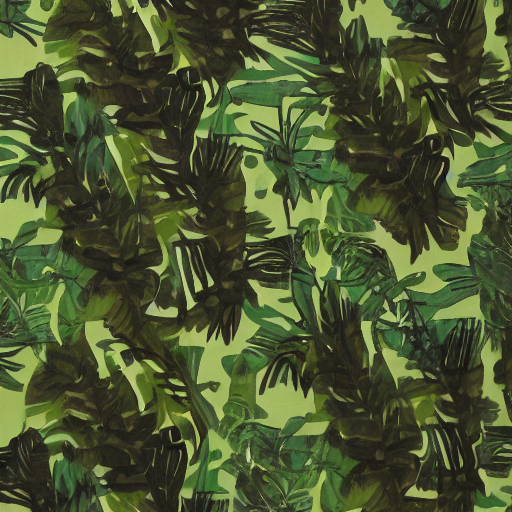

In [5]:
imgD

In [19]:
from pathlib import Path

from ultralytics import YOLO
from PIL import Image
import numpy as np
import torch
from meshrender import TextureRenderModel
from utils import load_uv_mask


def TestASR(
    imgD,
    img_size=1024,
    background=None,
    save_img=False,
    model_path="/home/dk/project/FastAdv/yolomodel/yolo12m.pt",
):
    model = YOLO(model_path)
    texture_render_model = TextureRenderModel(
        device="cuda",
        uv_mask=load_uv_mask("modified_mask.png", img_size, "cuda"),
        render_image_size=img_size,
        texture_image_size=img_size,
        background_fill_value=0.0,
    )
    texture_render_model.cuda()

    # 统计变量
    detected = 0  # 检测到车的视角数
    not_detected = 0  # 未检测到车的视角数
    total = 0

    # YOLO COCO 中 car=2, truck=7, bus=5，按需调整
    CAR_CLASSES = {2}

    for elev in [10, 20]:
        for azim in range(0, 360, 5):
            total += 1
            cam = texture_render_model.get_camera(dist=8.0, elev=elev, azim=azim)

            imgDD = (
                torch.from_numpy(np.array(imgD)).permute(2, 0, 1).unsqueeze(0).float()
                / 255.0
            )
            imgDD = imgDD.to("cuda")
            if background is None:
                img = texture_render_model(cam, imgDD)[..., :3]
            else:
                img = texture_render_model(cam, imgDD, background)[..., :3]
            # img = texture_render_model(cam, torch.ones_like(imgDD))
            img = img.permute(0, 3, 1, 2).clamp(0, 1)

            results = model(img, verbose=False, conf=0.25)

            view_has_car = False
            for i, r in enumerate(results):
                if r.boxes is not None and len(r.boxes) > 0:
                    classes = r.boxes.cls.cpu().numpy().astype(int)
                    if any(c in CAR_CLASSES for c in classes):
                        view_has_car = True

                im_bgr = r.plot()
                im_rgb = Image.fromarray(im_bgr[..., ::-1])
                save_path = Path("./") / "saved_results"
                if save_img:
                    save_path.mkdir(exist_ok=True)
                    r.save(filename=f"{save_path}/results_{elev}_{azim}_{i}.jpg")

            if view_has_car:
                detected += 1
            else:
                not_detected += 1
    rate = f"{detected / total * 100:.1f}%"
    # 构造字典（键名和你打印的文本完全对应）
    result = {
        "总视角数": total,
        "检测到车": detected,
        "未检测到车": not_detected,
        "检测率": rate,
    }
    return result


# TestASR(imgD)

## 测试有无lora的攻击成功率

In [7]:
# 加载背景数据集
import itertools

from data.bgdataset import get_background_dataloader

dataloader = get_background_dataloader(
    "data/background", category=["jungle", "sunset"], batch_size=1, shaffle=False
)
infinite_loader = itertools.cycle(dataloader)

# 无论调用多少次都不会报错
batch = next(infinite_loader)


In [8]:
batch.shape

torch.Size([1, 3, 640, 640])

In [ ]:
# 加载提示词（有lora）
from data import snow_prompts, urban_prompts, desert_prompts, jungle_prompts, to_clean
import torch

jungle_prompts1 = [
    # 核心纹理描述（增强 pattern 属性）
    "a seamless repeating jungle camouflage , green brown texture",
    "seamless woodland camouflage, dark green irregular repeating shapes",
    "tileable jungle camo , green brown black mottled texture",
    "seamless forest camouflage , multi-tone green organic repeating forms",
    "repeating jungle camo , dense dark green brown blotches texture",
    "tileable woodland camo , olive green dark repeating patches",
    "seamless jungle camouflage , layered green brown repeating shapes",
    "tileable forest camo , irregular dark green black repeating patches",
    "seamless jungle camouflage , diffuse green brown repeating forms",
    "repeating woodland camo , deep green ochre irregular blobs",
]
p = [
    # "sks zebra, black and white stripes, animal print, zebra texture, high detail, clean lines, smooth gradient, realistic",
    # "a sks cat",
    # "a cat ",
    "red realistic zebra skin texture, natural zebra stripes, seamless texture"
]
# 加载pipeline
categories = {
    # "snow": snow_prompts,
    "urban": p,
    # "desert": desert_prompts,
    # "jungle": desert_prompts
}

# 也可以选择 clean 参数，看需求
# 这里我们在字典里存放原提示词，如果需要去掉 sks，可以在生成时调用 to_clean

print(f"Loaded {len(categories)} categories.")
for k, v in categories.items():
    print(f" - {k}: {len(v)} prompts")

# 加载pipeline
# pipeline = get_pipeline("rank64_0402/pytorch_lora_weights.safetensors")
# pipeline = get_pipeline("rank64_0402/checkpoint-100/pytorch_lora_weights.safetensors")
pipeline = get_pipeline("rank64_0402/checkpoint-500/pytorch_lora_weights.safetensors")
# pipeline = get_pipeline()
shape = (1, 4, 64, 64)

# 遍历每个 prompt，并使用 10 个随机种子生成与测试
for cat_name, prompts in categories.items():
    for prompt in prompts:
        clean_prompt = prompt  # 如需要清理可改成 to_clean(prompt)
        # clean_prompt = to_clean(prompt) # 如需要清理可改成 to_clean(prompt)
        for seed in range(1, 2):
            generator = torch.Generator(device="cuda").manual_seed(seed)
            latents = torch.randn(
                shape,
                generator=generator,
                device=pipeline.device,
                dtype=pipeline.unet.dtype,
            )

            # 重新 seed，因为 randn 已经消耗了 generator 的状态
            generator = torch.Generator(device="cuda").manual_seed(seed)
            with torch.no_grad():
                imgD = pipeline(
                    clean_prompt,
                    num_inference_steps=25,
                    generator=generator,  # 必须传入
                    latents=latents,
                    # guidance_rescale= 7.5
                ).images[0]
            imgD.save(
                f"genpatch/lora_{cat_name}_{seed}_{clean_prompt.replace(',', '_')}.png"
            )  # 保存生成的图像

            # 测试ASR
            # back_ground = next(infinite_loader).to("cuda")
            # back_ground = Image.open("data/background/sunset/sunset_00002.jpg")
            back_ground = Image.open("data/background/snow/snow_00002.jpg")
            # imgD = imgD.convert("L").convert("RGB")  # 确保是 RGB 模式
            # bgr_np = np.array(imgD)[..., ::-1]
            # imgD = Image.fromarray(bgr_np)  # 转回 PIL 图像
            # imgD = imgD.convert("L").convert("RGB")  # 确保是 RGB 模式
            # asr_result = TestASR(imgD,img_size=640,background=back_ground,save_img=False)
            asr_result = TestASR(
                imgD,
                img_size=640,
                save_img=False,
                model_path="/home/dk/project/FastAdv/yolomodel/yolo12m.pt",
            )

            print(f"Prompt: {clean_prompt}")
            print(f"Seed: {seed}")
            print(f"ASR Result: {asr_result}")
            print("-" * 50)


Loaded 1 categories.
 - urban: 1 prompts


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 9890.92it/s]7.95it/s]
CLIPTextModel LOAD REPORT from: /home/dk/data/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 15.43it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly rec

Prompt: red realistic zebra skin texture, natural zebra stripes, seamless texture
Seed: 1
ASR Result: {'总视角数': 144, '检测到车': 0, '未检测到车': 144, '检测率': '0.0%'}
--------------------------------------------------


In [13]:
# 加载提示词（有lora）
from data import snow_prompts, urban_prompts, desert_prompts, jungle_prompts, to_clean
import torch

# 加载pipeline
categories = {
    # "snow": snow_prompts,
    # "urban": urban_prompts,
    # "desert": desert_prompts,
    "jungle": jungle_prompts
}

# 也可以选择 clean 参数，看需求
# 这里我们在字典里存放原提示词，如果需要去掉 sks，可以在生成时调用 to_clean

print(f"Loaded {len(categories)} categories.")
for k, v in categories.items():
    print(f" - {k}: {len(v)} prompts")

# 加载pipeline
# pipeline = get_pipeline("rank64_0402/pytorch_lora_weights.safetensors")
pipeline = get_pipeline()
shape = (1, 4, 64, 64)

# 遍历每个 prompt，并使用 10 个随机种子生成与测试
for cat_name, prompts in categories.items():
    for prompt in prompts:
        # clean_prompt = prompt # 如需要清理可改成 to_clean(prompt)
        clean_prompt = to_clean(prompt) # 如需要清理可改成 to_clean(prompt)
        for seed in range(1, 2):
            generator = torch.Generator(device="cuda").manual_seed(seed)
            latents = torch.randn(shape, generator=generator, device=pipeline.device, dtype=pipeline.unet.dtype)
            
            # 重新 seed，因为 randn 已经消耗了 generator 的状态
            generator = torch.Generator(device="cuda").manual_seed(seed)
            with torch.no_grad():
                imgD = pipeline(
                    clean_prompt,
                    num_inference_steps=20,
                    generator=generator,  # 必须传入
                    latents=latents,
                    # guidance_rescale= 7.5
                ).images[0]
            imgD.save(f'genpatch/lora_{cat_name}_{seed}_{clean_prompt.replace(",","_")}.png')  # 保存生成的图像
            
            # 测试ASR
            # back_ground = next(infinite_loader).to("cuda")
            back_ground = Image.open("data/background/sunset/sunset_00002.jpg")
            asr_result = TestASR(imgD,background=back_ground,save_img=False)
            
            print(f"Prompt: {clean_prompt}")
            print(f"Seed: {seed}")
            print(f"ASR Result: {asr_result}")
            print("-" * 50)


Loaded 1 categories.
 - jungle: 40 prompts


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 9267.72it/s]]
CLIPTextModel LOAD REPORT from: /home/dk/data/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 21.54it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend t

Prompt: a photo of jungle camouflage texture, green brown pattern
Seed: 1
ASR Result: {'总视角数': 144, '检测到车': 118, '未检测到车': 26, '检测率': '81.9%'}
--------------------------------------------------


100%|██████████| 20/20 [00:00<00:00, 20.32it/s]


Prompt: woodland camouflage pattern, dark green irregular shapes
Seed: 1
ASR Result: {'总视角数': 144, '检测到车': 43, '未检测到车': 101, '检测率': '29.9%'}
--------------------------------------------------


100%|██████████| 20/20 [00:00<00:00, 20.38it/s]


... (5 outputs left out)

100%|██████████| 20/20 [00:00<00:00, 20.52it/s]


Prompt: woodland camo texture, olive green dark patches
Seed: 1
ASR Result: {'总视角数': 144, '检测到车': 74, '未检测到车': 70, '检测率': '51.4%'}
--------------------------------------------------


 65%|██████▌   | 13/20 [00:00<00:00, 18.83it/s]


KeyboardInterrupt: 

In [37]:
# 测试Loar
from data import get_prompt_count
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "6"
import torch
from diffusers import StableDiffusionPipeline,ControlNetModel  # type: ignore

# controlnet = ControlNetModel.from_pretrained(
#     "controlnet-model",  # 训练输出目录
#     torch_dtype=torch.float32
# )
pipeline = StableDiffusionPipeline.from_pretrained(
    "/home/dk/data/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14",
    torch_dtype=torch.float32,
    # variant="fp16", 
    safety_checker=None,
    # controlnet = controlnet
    # local_files_only=True
)
pipeline.to("cuda")
# pipeline("a photo of TQL Camouflage",num_inference_steps=50).images[0]
print(1)

Loading weights: 100%|██████████| 196/196 [00:00<00:00, 2017.84it/s]]
CLIPTextModel LOAD REPORT from: /home/dk/data/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading pipeline components...:  17%|█▋        | 1/6 [00:02<00:13,  2.66s/it]


KeyboardInterrupt: 

## 生成数据集

In [ ]:
# 1. 加载所有类别的提示词
from data import snow_prompts, urban_prompts, desert_prompts, jungle_prompts, to_clean

categories = {
    "snow": snow_prompts,
    "urban": urban_prompts,
    "desert": desert_prompts,
    "jungle": jungle_prompts
}

# 也可以选择 clean 参数，看需求
# 这里我们在字典里存放原提示词，如果需要去掉 sks，可以在生成时调用 to_clean

print(f"Loaded {len(categories)} categories.")
for k, v in categories.items():
    print(f" - {k}: {len(v)} prompts")


Loaded 4 categories.
 - snow: 40 prompts
 - urban: 40 prompts
 - desert: 40 prompts
 - jungle: 40 prompts


In [ ]:
# 2. 初始化输出目录和常量
import os

N = 15  # 每个提示词生成 50 张图
output_root = "./data/generated_by_prompt"

# 创建根目录
os.makedirs(output_root, exist_ok=True)

# 创建并打开总映射文件 (追加与写入模式皆可，这里我们使用覆盖写入)
map_all_path = os.path.join(output_root, "prompt_image_map_all.txt")

# 为每个大类创建文件夹
for cat in categories.keys():
    cat_dir = os.path.join(output_root, cat)
    os.makedirs(cat_dir, exist_ok=True)

print(f"Output directories setup at: {output_root}")


Output directories setup at: ./data/generated_by_prompt


In [ ]:
# 3. 批量生成并记录映射
from tqdm.auto import tqdm
import torch
import random
# 基础 seed，用于组合生成每张图的确定性 seed
base_seed = 42

all_mappings = []

# 以写入模式打开总表
with open(map_all_path, "w", encoding="utf-8") as f_all:
    f_all.write("category,prompt,image_path,seed\n")
    
    # 遍历每个类别
    for cat, prompts in categories.items():
        cat_dir = os.path.join(output_root, cat)
        cat_map_path = os.path.join(cat_dir, "prompt_image_map.txt")
        
        print(f"\nGenerating for category: {cat} ({len(prompts)} prompts, {N} images each)")
        
        # 打开该类别专属的表
        with open(cat_map_path, "w", encoding="utf-8") as f_cat:
            f_cat.write("prompt,image_path,seed\n")
            
            # 使用 tqdm 显示进度
            for p_idx, prompt in enumerate(tqdm(prompts, desc=cat)):
                prompt_to_use = to_clean(prompt)  # 如果需要去掉 sks，可以在这里调用 to_clean
                for i in range(N):
                    # 每个样本的种子可以通过组合以确保可以复现
                    current_seed = base_seed + hash(prompt) % 10000 + i
                    generator = torch.Generator(device="cuda").manual_seed(current_seed)
                    
                    # 生成图像
                    img_output = pipeline(
                        prompt_to_use,
                        num_inference_steps=random.randint(15, 35),  # 可以随机调整步数增加多样性
                        generator=generator,
                    ).images[0]
                    
                    # 确定文件名及保存位置
                    img_name = f"prompt{p_idx:03d}_{i:03d}.jpg"
                    img_path = os.path.join(cat_dir, img_name)
                    
                    # 按照 RGB 保存
                    img_output.save(img_path)
                    
                    # 写出相对路径
                    rel_img_path = os.path.relpath(img_path, start=".")
                    
                    # 记录信息
                    mapping_inf = f"{cat},{prompt},{rel_img_path},{current_seed}\n"
                    f_all.write(mapping_inf)
                    
                    cat_inf = f"{prompt},{rel_img_path},{current_seed}\n"
                    f_cat.write(cat_inf)

print("\nGeneration completed!")


Generating for category: snow (40 prompts, 15 images each)


snow: 100%|██████████| 40/40 [29:09<00:00, 43.74s/it]



Generating for category: urban (40 prompts, 15 images each)


urban: 100%|██████████| 40/40 [28:48<00:00, 43.22s/it]



Generating for category: desert (40 prompts, 15 images each)


desert: 100%|██████████| 40/40 [28:41<00:00, 43.03s/it]



Generating for category: jungle (40 prompts, 15 images each)


jungle: 100%|██████████| 40/40 [28:25<00:00, 42.64s/it]


Generation completed!
